ADABOOST CLASSIFIER FOR CRIME HOTSPOT PREDICTION

STEP 2: DATA LOADING AND PREPROCESSING
Original dataset shape: (24148, 25)
Modeling table shape: (11152, 6)
Total crime records used: 23942

STEP 3: TRAIN-TEST SPLIT
Train rows: 8552 | Test rows: 2600
HOTSPOT threshold (75th percentile): 3.0
Train HOTSPOT rate: 0.329
Test HOTSPOT rate: 0.248
Encoded feature shape: (8552, 49)
Class distribution - Train: {0: np.int64(5739), 1: np.int64(2813)}
Class distribution - Test: {0: np.int64(1955), 1: np.int64(645)}

STEP 4: ADABOOST BASELINE MODEL

AdaBoost Baseline Results:
--------------------------------------------------
Base Estimator: DecisionTreeClassifier(max_depth=3)
n_estimators: 100
learning_rate: 0.5
--------------------------------------------------
Accuracy:  0.7435
Precision: 0.4633
Recall:    0.2155
F1 Score:  0.2942
ROC-AUC:   0.7145
Train Time: 0.347 seconds

Confusion Matrix (Baseline):
[[1794  161]
 [ 506  139]]

STEP 5: HYPERPARAMETER TUNING WITH GRIDSEARCHCV
Parameter Grid:
 

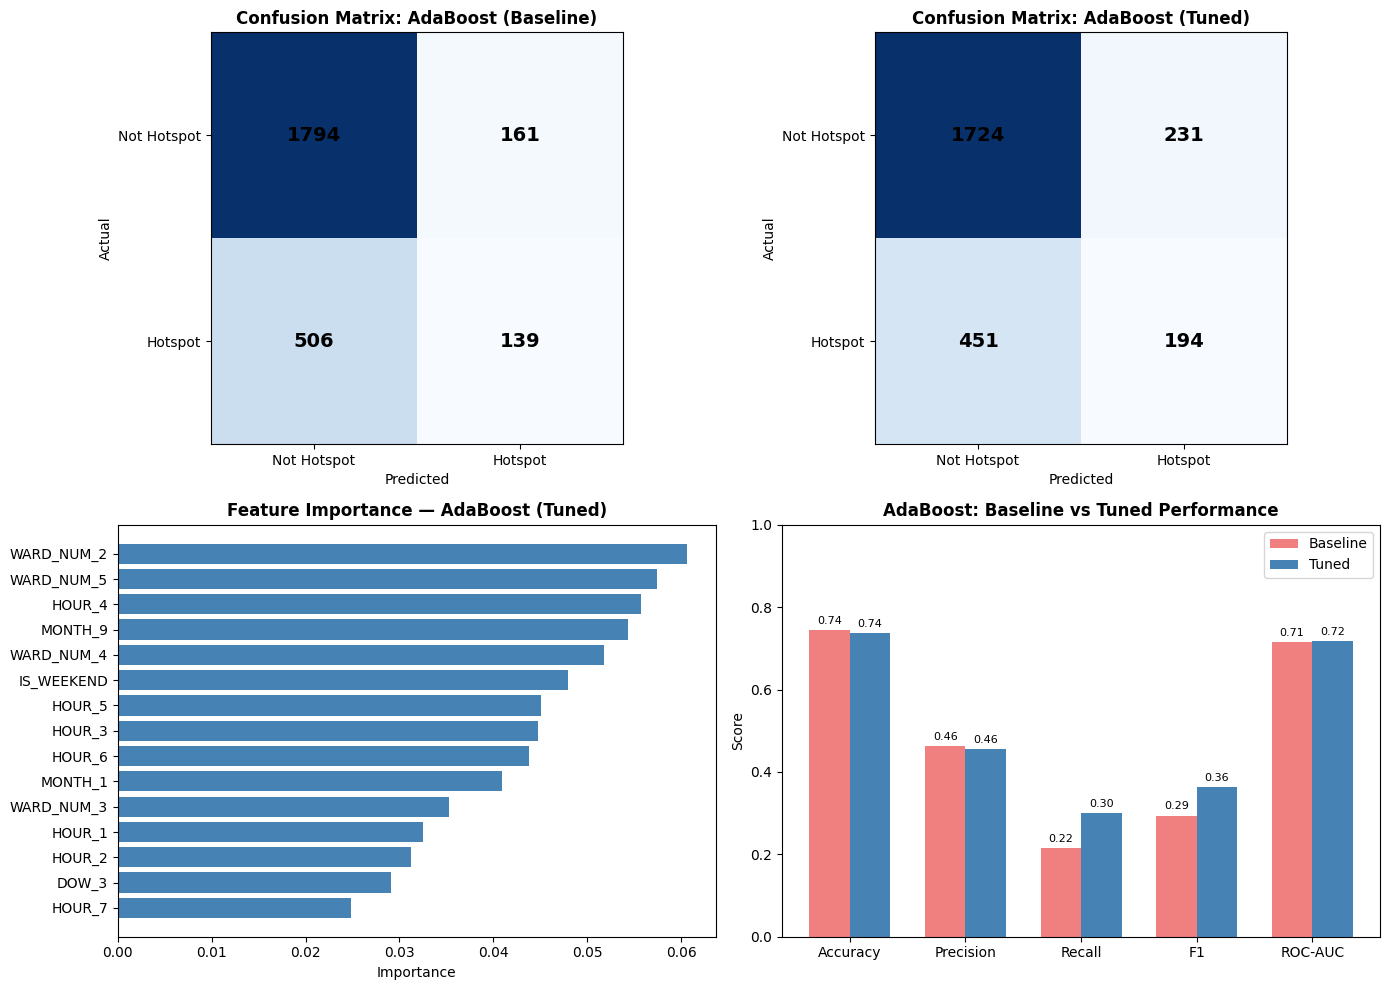

✓ Visualizations saved!

STEP 9: ROC CURVE


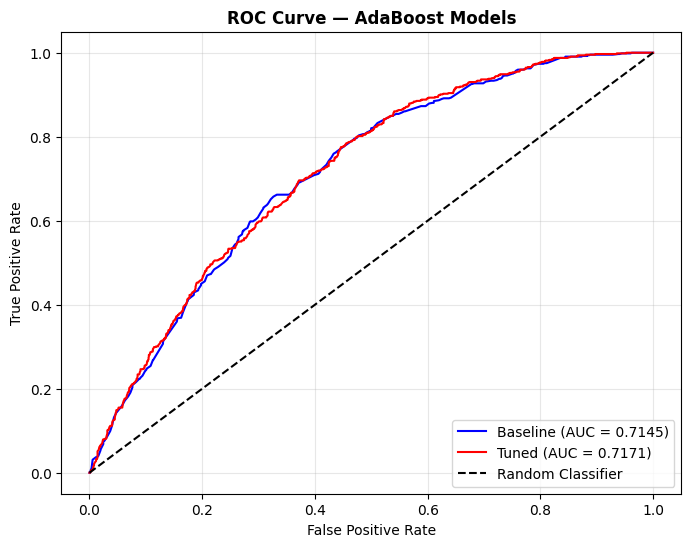

✓ ROC Curve saved!

STEP 10: FINAL SUMMARY TABLE FOR REPORT

              Model        Base Estimator  n_estimators  learning_rate  Accuracy  Precision  Recall     F1  ROC_AUC  Time(sec)
AdaBoost (Baseline) DecisionTree(depth=3)           100            0.5    0.7435     0.4633  0.2155 0.2942   0.7145      0.347
   AdaBoost (Tuned) DecisionTree(depth=3)           200            1.0    0.7377     0.4565  0.3008 0.3626   0.7171      5.440


Formatted for Report:
----------------------------------------------------------------------------------------------------
Model                        n_est     lr      Acc     Prec   Recall       F1      AUC       Time
----------------------------------------------------------------------------------------------------
AdaBoost (Baseline)            100    0.5   0.7435   0.4633   0.2155   0.2942   0.7145      0.347
AdaBoost (Tuned)               200    1.0   0.7377   0.4565   0.3008   0.3626   0.7171       5.44
--------------------------------------

In [1]:
# ADABOOST CLASSIFIER FOR CRIME HOTSPOT PREDICTION
# ALY6040 - Assignment 3
# Name: Dev Bhadreshkumar Panchal

# STEP 1: IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)
from sklearn.model_selection import GridSearchCV
import time
import warnings
warnings.filterwarnings('ignore')

print("="*70)
print("ADABOOST CLASSIFIER FOR CRIME HOTSPOT PREDICTION")
print("="*70)

# STEP 2: LOAD AND PREPROCESS DATA
print("\n" + "="*70)
print("STEP 2: DATA LOADING AND PREPROCESSING")
print("="*70)
df = pd.read_csv('Crime_Incidents_-_2025.csv')
df['START_DATE'] = pd.to_datetime(df['START_DATE'], utc=True)
df['REPORT_DAT'] = pd.to_datetime(df['REPORT_DAT'], utc=True)
print(f"Original dataset shape: {df.shape}")

# Filter to 2025 data and prepare features
df_model_src = df.dropna(subset=["START_DATE"]).copy()
df_model_src = df_model_src[df_model_src["START_DATE"].dt.year == 2025].copy()

# Convert to Eastern Time (Washington D.C. local time)
df_model_src["START_LOCAL"] = df_model_src["START_DATE"].dt.tz_convert("America/New_York")

# Feature Engineering 
df_model_src["MONTH"] = df_model_src["START_LOCAL"].dt.month
df_model_src["DOW"] = df_model_src["START_LOCAL"].dt.dayofweek  # 0=Monday
df_model_src["HOUR"] = df_model_src["START_LOCAL"].dt.hour
df_model_src["IS_WEEKEND"] = df_model_src["DOW"].isin([5, 6]).astype(int)

# Ward cleaning
df_model_src["WARD_NUM"] = pd.to_numeric(df_model_src["WARD"], errors="coerce")
df_model_src = df_model_src[df_model_src["WARD_NUM"].between(1, 8)].copy()

# Aggregate into Ward × Time buckets
model_df = (
    df_model_src
    .groupby(["WARD_NUM", "MONTH", "DOW", "HOUR", "IS_WEEKEND"])
    .size()
    .reset_index(name="INCIDENT_COUNT")
)

print(f"Modeling table shape: {model_df.shape}")
print(f"Total crime records used: {len(df_model_src)}")
model_df.head()

# STEP 3: TRAIN-TEST SPLIT (Time-based)
print("\n" + "="*70)
print("STEP 3: TRAIN-TEST SPLIT")
print("="*70)

# Time-based split: Train (Jan-Sep), Test (Oct-Dec)
train_df = model_df[model_df["MONTH"] <= 9].copy()
test_df = model_df[model_df["MONTH"] >= 10].copy()

print(f"Train rows: {len(train_df)} | Test rows: {len(test_df)}")

# Define HOTSPOT threshold from training data only (75th percentile)
threshold = train_df["INCIDENT_COUNT"].quantile(0.75)
train_df["HOTSPOT"] = (train_df["INCIDENT_COUNT"] >= threshold).astype(int)
test_df["HOTSPOT"] = (test_df["INCIDENT_COUNT"] >= threshold).astype(int)

print(f"HOTSPOT threshold (75th percentile): {threshold}")
print(f"Train HOTSPOT rate: {train_df['HOTSPOT'].mean():.3f}")
print(f"Test HOTSPOT rate: {test_df['HOTSPOT'].mean():.3f}")

# Prepare features
feature_cols = ["WARD_NUM", "MONTH", "DOW", "HOUR", "IS_WEEKEND"]
X_train = train_df[feature_cols].copy()
y_train = train_df["HOTSPOT"].copy()
X_test = test_df[feature_cols].copy()
y_test = test_df["HOTSPOT"].copy()

# One-hot encoding
X_train_enc = pd.get_dummies(X_train.astype(int), columns=["WARD_NUM", "MONTH", "DOW", "HOUR"], drop_first=False)
X_test_enc = pd.get_dummies(X_test.astype(int), columns=["WARD_NUM", "MONTH", "DOW", "HOUR"], drop_first=False)
X_test_enc = X_test_enc.reindex(columns=X_train_enc.columns, fill_value=0)

print(f"Encoded feature shape: {X_train_enc.shape}")
print(f"Class distribution - Train: {dict(y_train.value_counts())}")
print(f"Class distribution - Test: {dict(y_test.value_counts())}")

# STEP 4: ADABOOST BASELINE MODEL
print("\n" + "="*70)
print("STEP 4: ADABOOST BASELINE MODEL")
print("="*70)

# AdaBoost with Decision Tree (depth=3) as base estimator
# Note: Default base estimator is DecisionTreeClassifier with max_depth=1 (decision stump)

base_estimator = DecisionTreeClassifier(max_depth=3, random_state=42)
ada_baseline = AdaBoostClassifier(
    estimator=base_estimator,
    n_estimators=100,
    learning_rate=0.5,
    algorithm='SAMME',  # SAMME.R is deprecated in newer sklearn versions
    random_state=42
)

# Train and measure time
start_time = time.perf_counter()
ada_baseline.fit(X_train_enc, y_train)
train_time_baseline = time.perf_counter() - start_time

# Predictions
y_pred_baseline = ada_baseline.predict(X_test_enc)
y_proba_baseline = ada_baseline.predict_proba(X_test_enc)[:, 1]

# Display metrics
print("\nAdaBoost Baseline Results:")
print("-" * 50)
print(f"Base Estimator: DecisionTreeClassifier(max_depth=3)")
print(f"n_estimators: 100")
print(f"learning_rate: 0.5")
print("-" * 50)
print(f"Accuracy:  {accuracy_score(y_test, y_pred_baseline):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_baseline):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_baseline):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_baseline):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba_baseline):.4f}")
print(f"Train Time: {train_time_baseline:.3f} seconds")

# Confusion Matrix
cm_baseline = confusion_matrix(y_test, y_pred_baseline)
print(f"\nConfusion Matrix (Baseline):")
print(cm_baseline)

# STEP 5: HYPERPARAMETER TUNING WITH GRIDSEARCHCV
print("\n" + "="*70)
print("STEP 5: HYPERPARAMETER TUNING WITH GRIDSEARCHCV")
print("="*70)

# Define parameter grid
param_grid = {
    'n_estimators': [50, 100, 150, 200],
    'learning_rate': [0.1, 0.3, 0.5, 1.0],
}

# Base AdaBoost model for tuning
ada_grid = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=3, random_state=42),
    algorithm='SAMME',
    random_state=42
)

print("Parameter Grid:")
print(f"  n_estimators: {param_grid['n_estimators']}")
print(f"  learning_rate: {param_grid['learning_rate']}")
print(f"  Total combinations: {len(param_grid['n_estimators']) * len(param_grid['learning_rate'])}")

# Run GridSearchCV
start_tune = time.perf_counter()
gs = GridSearchCV(
    ada_grid, 
    param_grid, 
    scoring='f1', 
    cv=3, 
    n_jobs=-1,
    verbose=1
)
gs.fit(X_train_enc, y_train)
tune_time = time.perf_counter() - start_tune

print(f"\nTuning completed in {tune_time:.2f} seconds")
print(f"Best Parameters: {gs.best_params_}")
print(f"Best CV F1 Score: {gs.best_score_:.4f}")

# STEP 6: TUNED ADABOOST MODEL EVALUATION
print("\n" + "="*70)
print("STEP 6: TUNED ADABOOST MODEL EVALUATION")
print("="*70)

# Get best model
ada_tuned = gs.best_estimator_

# Predictions
y_pred_tuned = ada_tuned.predict(X_test_enc)
y_proba_tuned = ada_tuned.predict_proba(X_test_enc)[:, 1]

# Display metrics
print("\nAdaBoost Tuned Results:")
print("-" * 50)
print(f"Best Parameters: {gs.best_params_}")
print("-" * 50)
print(f"Accuracy:  {accuracy_score(y_test, y_pred_tuned):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_tuned):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_tuned):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_tuned):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba_tuned):.4f}")
print(f"Tuning Time: {tune_time:.2f} seconds")

# Confusion Matrix
cm_tuned = confusion_matrix(y_test, y_pred_tuned)
print(f"\nConfusion Matrix (Tuned):")
print(cm_tuned)

# Classification Report
print("\nClassification Report (Tuned Model):")
print(classification_report(y_test, y_pred_tuned, target_names=['Not Hotspot', 'Hotspot']))

# STEP 7: FEATURE IMPORTANCE ANALYSIS
print("\n" + "="*70)
print("STEP 7: FEATURE IMPORTANCE ANALYSIS")
print("="*70)

# Get feature importance
feature_importance = pd.Series(
    ada_tuned.feature_importances_, 
    index=X_train_enc.columns
).sort_values(ascending=False)

print("\nTop 20 Most Important Features:")
print("-" * 50)
for i, (feat, imp) in enumerate(feature_importance.head(20).items(), 1):
    print(f"{i:2}. {feat:<20}: {imp:.4f}")

# STEP 8: VISUALIZATIONS
print("\n" + "="*70)
print("STEP 8: VISUALIZATIONS")
print("="*70)

# Create figure with subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Confusion Matrix - Baseline
ax1 = axes[0, 0]
im1 = ax1.imshow(cm_baseline, cmap='Blues')
ax1.set_title('Confusion Matrix: AdaBoost (Baseline)', fontsize=12, fontweight='bold')
ax1.set_xticks([0, 1])
ax1.set_yticks([0, 1])
ax1.set_xticklabels(['Not Hotspot', 'Hotspot'])
ax1.set_yticklabels(['Not Hotspot', 'Hotspot'])
ax1.set_xlabel('Predicted')
ax1.set_ylabel('Actual')
for i in range(2):
    for j in range(2):
        ax1.text(j, i, cm_baseline[i, j], ha='center', va='center', fontsize=14, fontweight='bold')

# 2. Confusion Matrix - Tuned
ax2 = axes[0, 1]
im2 = ax2.imshow(cm_tuned, cmap='Blues')
ax2.set_title('Confusion Matrix: AdaBoost (Tuned)', fontsize=12, fontweight='bold')
ax2.set_xticks([0, 1])
ax2.set_yticks([0, 1])
ax2.set_xticklabels(['Not Hotspot', 'Hotspot'])
ax2.set_yticklabels(['Not Hotspot', 'Hotspot'])
ax2.set_xlabel('Predicted')
ax2.set_ylabel('Actual')
for i in range(2):
    for j in range(2):
        ax2.text(j, i, cm_tuned[i, j], ha='center', va='center', fontsize=14, fontweight='bold')

# 3. Feature Importance
ax3 = axes[1, 0]
top_features = feature_importance.head(15)
ax3.barh(range(len(top_features)), top_features.values[::-1], color='steelblue')
ax3.set_yticks(range(len(top_features)))
ax3.set_yticklabels(top_features.index[::-1])
ax3.set_xlabel('Importance')
ax3.set_title('Feature Importance — AdaBoost (Tuned)', fontsize=12, fontweight='bold')

# 4. Model Comparison Bar Chart
ax4 = axes[1, 1]
metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
baseline_vals = [
    accuracy_score(y_test, y_pred_baseline),
    precision_score(y_test, y_pred_baseline),
    recall_score(y_test, y_pred_baseline),
    f1_score(y_test, y_pred_baseline),
    roc_auc_score(y_test, y_proba_baseline)
]
tuned_vals = [
    accuracy_score(y_test, y_pred_tuned),
    precision_score(y_test, y_pred_tuned),
    recall_score(y_test, y_pred_tuned),
    f1_score(y_test, y_pred_tuned),
    roc_auc_score(y_test, y_proba_tuned)
]

x = np.arange(len(metrics))
width = 0.35
bars1 = ax4.bar(x - width/2, baseline_vals, width, label='Baseline', color='lightcoral')
bars2 = ax4.bar(x + width/2, tuned_vals, width, label='Tuned', color='steelblue')
ax4.set_ylabel('Score')
ax4.set_title('AdaBoost: Baseline vs Tuned Performance', fontsize=12, fontweight='bold')
ax4.set_xticks(x)
ax4.set_xticklabels(metrics)
ax4.legend()
ax4.set_ylim(0, 1)

# Add value labels on bars
for bar in bars1:
    height = bar.get_height()
    ax4.annotate(f'{height:.2f}', xy=(bar.get_x() + bar.get_width()/2, height),
                 xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8)
for bar in bars2:
    height = bar.get_height()
    ax4.annotate(f'{height:.2f}', xy=(bar.get_x() + bar.get_width()/2, height),
                 xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('adaboost_results.png', dpi=150, bbox_inches='tight')
plt.show()

print("✓ Visualizations saved!")

# STEP 9: ROC CURVE
print("\n" + "="*70)
print("STEP 9: ROC CURVE")
print("="*70)

# Calculate ROC curves
fpr_baseline, tpr_baseline, _ = roc_curve(y_test, y_proba_baseline)
fpr_tuned, tpr_tuned, _ = roc_curve(y_test, y_proba_tuned)

# Plot ROC curves
plt.figure(figsize=(8, 6))
plt.plot(fpr_baseline, tpr_baseline, 'b-', label=f'Baseline (AUC = {roc_auc_score(y_test, y_proba_baseline):.4f})')
plt.plot(fpr_tuned, tpr_tuned, 'r-', label=f'Tuned (AUC = {roc_auc_score(y_test, y_proba_tuned):.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — AdaBoost Models', fontsize=12, fontweight='bold')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.savefig('adaboost_roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()

print("✓ ROC Curve saved!")

# STEP 10: FINAL SUMMARY TABLE
print("\n" + "="*70)
print("STEP 10: FINAL SUMMARY TABLE FOR REPORT")
print("="*70)

summary_df = pd.DataFrame([
    {
        "Model": "AdaBoost (Baseline)",
        "Base Estimator": "DecisionTree(depth=3)",
        "n_estimators": 100,
        "learning_rate": 0.5,
        "Accuracy": round(accuracy_score(y_test, y_pred_baseline), 4),
        "Precision": round(precision_score(y_test, y_pred_baseline), 4),
        "Recall": round(recall_score(y_test, y_pred_baseline), 4),
        "F1": round(f1_score(y_test, y_pred_baseline), 4),
        "ROC_AUC": round(roc_auc_score(y_test, y_proba_baseline), 4),
        "Time(sec)": round(train_time_baseline, 3)
    },
    {
        "Model": "AdaBoost (Tuned)",
        "Base Estimator": "DecisionTree(depth=3)",
        "n_estimators": gs.best_params_['n_estimators'],
        "learning_rate": gs.best_params_['learning_rate'],
        "Accuracy": round(accuracy_score(y_test, y_pred_tuned), 4),
        "Precision": round(precision_score(y_test, y_pred_tuned), 4),
        "Recall": round(recall_score(y_test, y_pred_tuned), 4),
        "F1": round(f1_score(y_test, y_pred_tuned), 4),
        "ROC_AUC": round(roc_auc_score(y_test, y_proba_tuned), 4),
        "Time(sec)": round(tune_time, 2)
    }
])

print("\n" + summary_df.to_string(index=False))

# Display as formatted table
print("\n\nFormatted for Report:")
print("-" * 100)
print(f"{'Model':<25} {'n_est':>8} {'lr':>6} {'Acc':>8} {'Prec':>8} {'Recall':>8} {'F1':>8} {'AUC':>8} {'Time':>10}")
print("-" * 100)
for _, row in summary_df.iterrows():
    print(f"{row['Model']:<25} {row['n_estimators']:>8} {row['learning_rate']:>6} {row['Accuracy']:>8} {row['Precision']:>8} {row['Recall']:>8} {row['F1']:>8} {row['ROC_AUC']:>8} {row['Time(sec)']:>10}")
print("-" * 100)

print("\n" + "="*70)
print("ADABOOST ANALYSIS COMPLETE!")
print("="*70)

In [1]:
import time
import numpy as np
import pandas as pd

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def eval_binary_classifier(name, model, Xtr, ytr, Xte, yte):
    start = time.perf_counter()
    model.fit(Xtr, ytr)
    train_time = time.perf_counter() - start

    pred = model.predict(Xte)

    # HistGradientBoostingClassifier uses decision_function; convert to probability-like score
    # If predict_proba exists, use it; otherwise use decision_function + sigmoid
    proba = None
    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(Xte)[:, 1]
    elif hasattr(model, "decision_function"):
        scores = model.decision_function(Xte)
        proba = 1 / (1 + np.exp(-scores))  # sigmoid

    return {
        "Model": name,
        "Accuracy": accuracy_score(yte, pred),
        "Precision": precision_score(yte, pred, zero_division=0),
        "Recall": recall_score(yte, pred, zero_division=0),
        "F1": f1_score(yte, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(yte, proba) if proba is not None else np.nan,
        "Train_Time_sec": train_time,
        "Fitted_Model": model
    }

# Baseline HGB (keep it simple for Week-2)
hgb = HistGradientBoostingClassifier(
    learning_rate=0.1,
    max_depth=6,
    max_iter=300,        # number of boosting iterations
    random_state=42
)

hgb_result = eval_binary_classifier("HistGB (Baseline)", hgb, X_train_enc, y_train, X_test_enc, y_test)

pd.DataFrame([{k:v for k,v in hgb_result.items() if k != "Fitted_Model"}])



from sklearn.model_selection import GridSearchCV

hgb_grid = {
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 5, 7, None],
    "max_iter": [200, 400],
    "min_samples_leaf": [10, 30, 60],
    "l2_regularization": [0.0, 0.1, 1.0]
}

hgb_base = HistGradientBoostingClassifier(random_state=42)

start = time.perf_counter()
hgb_gs = GridSearchCV(hgb_base, hgb_grid, scoring="f1", cv=3, n_jobs=-1)
hgb_gs.fit(X_train_enc, y_train)
tune_time = time.perf_counter() - start

best_hgb = hgb_gs.best_estimator_
pred = best_hgb.predict(X_test_enc)

# probability-like scores for AUC
if hasattr(best_hgb, "predict_proba"):
    proba = best_hgb.predict_proba(X_test_enc)[:, 1]
else:
    scores = best_hgb.decision_function(X_test_enc)
    proba = 1 / (1 + np.exp(-scores))

hgb_tuned_result = {
    "Model": "HistGB (Tuned)",
    "Best_Params": hgb_gs.best_params_,
    "Accuracy": accuracy_score(y_test, pred),
    "Precision": precision_score(y_test, pred, zero_division=0),
    "Recall": recall_score(y_test, pred, zero_division=0),
    "F1": f1_score(y_test, pred, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, proba),
    "Tuning_Time_sec": tune_time,
    "Fitted_Model": best_hgb
}

pd.DataFrame([{k:v for k,v in hgb_tuned_result.items() if k != "Fitted_Model"}])



import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

# Use tuned HGB if available; else baseline
model_for_explain = best_hgb if "best_hgb" in globals() else hgb_result["Fitted_Model"]

perm = permutation_importance(
    model_for_explain,
    X_test_enc,
    y_test,
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
    scoring="f1"
)

imp = pd.Series(perm.importances_mean, index=X_test_enc.columns).sort_values(ascending=False).head(20)

plt.figure(figsize=(10, 6))
plt.barh(imp.index[::-1], imp.values[::-1])
plt.title("Feature Importance (Permutation) — HistGradientBoosting (Top 20)")
plt.xlabel("Mean importance (ΔF1)")
plt.tight_layout()
plt.show()




import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

def get_proba_or_score(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    if hasattr(model, "decision_function"):
        scores = model.decision_function(X)
        return 1 / (1 + np.exp(-scores))
    # fallback (not ideal): use predictions as scores
    return model.predict(X)

# Choose which set to plot (baseline results or tuned results)
plot_models = []

# Example: plot tuned models if available
if "tuned_results" in globals() and len(tuned_results) > 0:
    plot_models = tuned_results
else:
    plot_models = results

# ROC curves
plt.figure(figsize=(8, 6))
for r in plot_models:
    model = r["Fitted_Model"]
    y_score = get_proba_or_score(model, X_test_enc)
    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{r['Model']} (AUC={roc_auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("ROC Curves (Test Set)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

# PR curves
plt.figure(figsize=(8, 6))
for r in plot_models:
    model = r["Fitted_Model"]
    y_score = get_proba_or_score(model, X_test_enc)
    precision, recall, _ = precision_recall_curve(y_test, y_score)
    ap = average_precision_score(y_test, y_score)
    plt.plot(recall, precision, label=f"{r['Model']} (AP={ap:.3f})")

plt.title("Precision–Recall Curves (Test Set)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.tight_layout()
plt.show()


NameError: name 'X_train_enc' is not defined